In [1]:
# Install required libraries
!pip install -q xarray netCDF4 pyarrow openap

# Import libraries
import pandas as pd
import numpy as np
import xarray as xr
import sqlite3
import matplotlib.pyplot as plt

from openap import FuelFlow

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd
import xarray as xr
import sqlite3
import numpy as np

observations = pd.read_parquet('/content/observations.parquet')
matches = pd.read_parquet('/content/matches.parquet')
flights = pd.read_parquet('/content/flights.parquet')
surface = xr.open_dataset('/content/era5t_oejn_2026-10-01_surface.nc')
pressure = xr.open_dataset('/content/era5_pressure_extended.nc')
conn = sqlite3.connect('/content/aeromux_db.sqlite')

print("All datasets loaded successfully!")
print("Observations:", observations.shape)
print("Flights:", flights.shape)
print("Surface dimensions:", surface.sizes)
print("Pressure dimensions:", pressure.sizes)

All datasets loaded successfully!
Observations: (622080, 36)
Flights: (872, 19)
Surface dimensions: Frozen({'time': 24, 'latitude': 13, 'longitude': 13})
Pressure dimensions: Frozen({'valid_time': 24, 'pressure_level': 24, 'latitude': 13, 'longitude': 13})


In [3]:
# Calculate surface weather variables

surface["wind_speed"] = np.sqrt(
    surface["10m_u_component_of_wind"]**2
    + surface["10m_v_component_of_wind"]**2
)

surface["temperature_C"] = (
    surface["2m_temperature"] - 273.15
)

surface["surface_pressure_hPa"] = (
    surface["surface_pressure"] / 100
)

print("Surface weather calculations completed!")

Surface weather calculations completed!


In [17]:
# Rename pressure-level variables

pressure = pressure.rename({
    "u": "u_component_of_wind",
    "v": "v_component_of_wind",
    "t": "temperature",
    "z": "geopotential"
})

# Calculate wind speed
pressure["wind_speed"] = np.sqrt(
    pressure["u_component_of_wind"]**2 +
    pressure["v_component_of_wind"]**2
)

# Convert temperature from Kelvin to Celsius
pressure["temperature_C"] = pressure["temperature"] - 273.15

# Convert geopotential to geopotential height in meters
pressure["geopotential_height_m"] = pressure["geopotential"] / 9.80665

print("Pressure-level variables renamed and calculated!")
print("Variables:", list(pressure.data_vars))

Pressure-level variables renamed and calculated!
Variables: ['u_component_of_wind', 'v_component_of_wind', 'temperature', 'geopotential', 'wind_speed', 'temperature_C', 'geopotential_height_m']


In [18]:
# Step 5: Check aircraft geographic coverage

print("AIRCRAFT COORDINATES")

print(
    "Latitude:",
    observations["latitude_deg"].min(),
    "to",
    observations["latitude_deg"].max()
)

print(
    "Longitude:",
    observations["longitude_deg"].min(),
    "to",
    observations["longitude_deg"].max()
)

print("\nERA5 GEOGRAPHIC COVERAGE")

print(
    "Latitude:",
    float(surface.latitude.min()),
    "to",
    float(surface.latitude.max())
)

print(
    "Longitude:",
    float(surface.longitude.min()),
    "to",
    float(surface.longitude.max())
)

# Identify observations inside ERA5 coverage

inside = (
    observations["latitude_deg"].between(
        float(surface.latitude.min()),
        float(surface.latitude.max())
    )
    &
    observations["longitude_deg"].between(
        float(surface.longitude.min()),
        float(surface.longitude.max())
    )
)

print("\nObservations inside ERA5 coverage:", inside.sum())
print("Observations outside ERA5 coverage:", (~inside).sum())

print(
    "Coverage percentage:",
    round(inside.mean() * 100, 2),
    "%"
)

AIRCRAFT COORDINATES
Latitude: 19.523986999999998 to 23.786378
Longitude: 37.236379 to 41.429094

ERA5 GEOGRAPHIC COVERAGE
Latitude: 20.0 to 23.0
Longitude: 38.0 to 41.0

Observations inside ERA5 coverage: 599089
Observations outside ERA5 coverage: 22991
Coverage percentage: 96.3 %


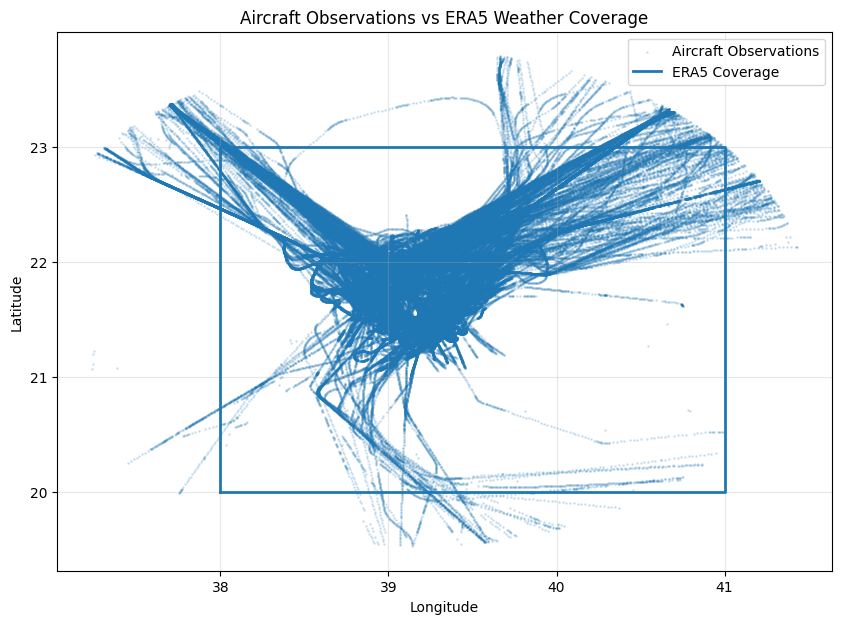

In [19]:
import matplotlib.pyplot as plt

# Plot aircraft locations and ERA5 coverage
plt.figure(figsize=(10, 7))

# Plot all aircraft observations
plt.scatter(
    observations["longitude_deg"],
    observations["latitude_deg"],
    s=1,
    alpha=0.15,
    label="Aircraft Observations"
)

# Plot ERA5 geographic coverage
plt.plot(
    [38, 41, 41, 38, 38],
    [20, 20, 23, 23, 20],
    linewidth=2,
    label="ERA5 Coverage"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Aircraft Observations vs ERA5 Weather Coverage")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [20]:
# Step 6: Match surface weather with aircraft observations

# Sort latitude because ERA5 latitude may be descending
surface_sorted = surface.sortby("latitude")

# Prepare output columns
weather_columns = [
    "wind_u_10m",
    "wind_v_10m",
    "wind_speed_10m",
    "temperature_2m_C",
    "surface_pressure_hPa"
]

# Initialize weather columns
for col in weather_columns:
    observations[col] = np.nan

# Process observations in chunks to reduce memory usage
chunk_size = 50000

for start in range(0, len(observations), chunk_size):

    end = min(start + chunk_size, len(observations))

    chunk = observations.iloc[start:end]
    valid = inside.iloc[start:end]

    if not valid.any():
        continue

    selected = chunk.loc[valid]

    times = (
        selected["timestamp_utc"]
        .dt.tz_localize(None)
        .to_numpy()
    )

    # Interpolate weather based on time and location
    weather = surface_sorted[
        [
            "10m_u_component_of_wind",
            "10m_v_component_of_wind",
            "wind_speed",
            "temperature_C",
            "surface_pressure_hPa"
        ]
    ].interp(
        time=xr.DataArray(times, dims="obs"),
        latitude=xr.DataArray(
            selected["latitude_deg"].to_numpy(), dims="obs"
        ),
        longitude=xr.DataArray(
            selected["longitude_deg"].to_numpy(), dims="obs"
        ),
        method="linear"
    )

    idx = selected.index

    observations.loc[idx, weather_columns] = np.column_stack([
        weather["10m_u_component_of_wind"].values,
        weather["10m_v_component_of_wind"].values,
        weather["wind_speed"].values,
        weather["temperature_C"].values,
        weather["surface_pressure_hPa"].values
    ])

    print(f"Processed {end:,} / {len(observations):,}")

print("\nSurface weather matching completed!")

Processed 50,000 / 622,080
Processed 100,000 / 622,080
Processed 150,000 / 622,080
Processed 200,000 / 622,080
Processed 250,000 / 622,080
Processed 300,000 / 622,080
Processed 350,000 / 622,080
Processed 400,000 / 622,080
Processed 450,000 / 622,080
Processed 500,000 / 622,080
Processed 550,000 / 622,080
Processed 600,000 / 622,080
Processed 622,080 / 622,080

Surface weather matching completed!


In [21]:
# Step 7: Check surface weather matching results

weather_columns = [
    "wind_u_10m",
    "wind_v_10m",
    "wind_speed_10m",
    "temperature_2m_C",
    "surface_pressure_hPa"
]

print("Total observations:", len(observations))

print("Matched observations:",
      observations["wind_speed_10m"].notna().sum())

print("Missing observations:",
      observations["wind_speed_10m"].isna().sum())

print("Coverage percentage:",
      round(observations["wind_speed_10m"].notna().mean() * 100, 2), "%")

print("\nMissing values by weather variable:")
print(observations[weather_columns].isna().sum())

Total observations: 622080
Matched observations: 575202
Missing observations: 46878
Coverage percentage: 92.46 %

Missing values by weather variable:
wind_u_10m              46878
wind_v_10m              46878
wind_speed_10m          46878
temperature_2m_C        46878
surface_pressure_hPa    46878
dtype: int64


In [22]:
# Step 8: Analyze missing weather observations

missing = observations["wind_speed_10m"].isna()

missing_inside = missing & inside
missing_outside = missing & ~inside

print("Total missing:", missing.sum())

print("Missing inside ERA5 coverage:", missing_inside.sum())

print("Missing outside ERA5 coverage:", missing_outside.sum())

print("\nERA5 time range:")
print("Start:", surface.time.min().values)
print("End:", surface.time.max().values)

print("\nMissing observations time range:")
print("Start:", observations.loc[missing, "timestamp_utc"].min())
print("End:", observations.loc[missing, "timestamp_utc"].max())

Total missing: 46878
Missing inside ERA5 coverage: 23887
Missing outside ERA5 coverage: 22991

ERA5 time range:
Start: 2026-10-01T00:00:00.000000000
End: 2026-10-01T23:00:00.000000000

Missing observations time range:
Start: 2026-10-01 00:17:00.924000+00:00
End: 2026-10-01 23:59:59.988000+00:00


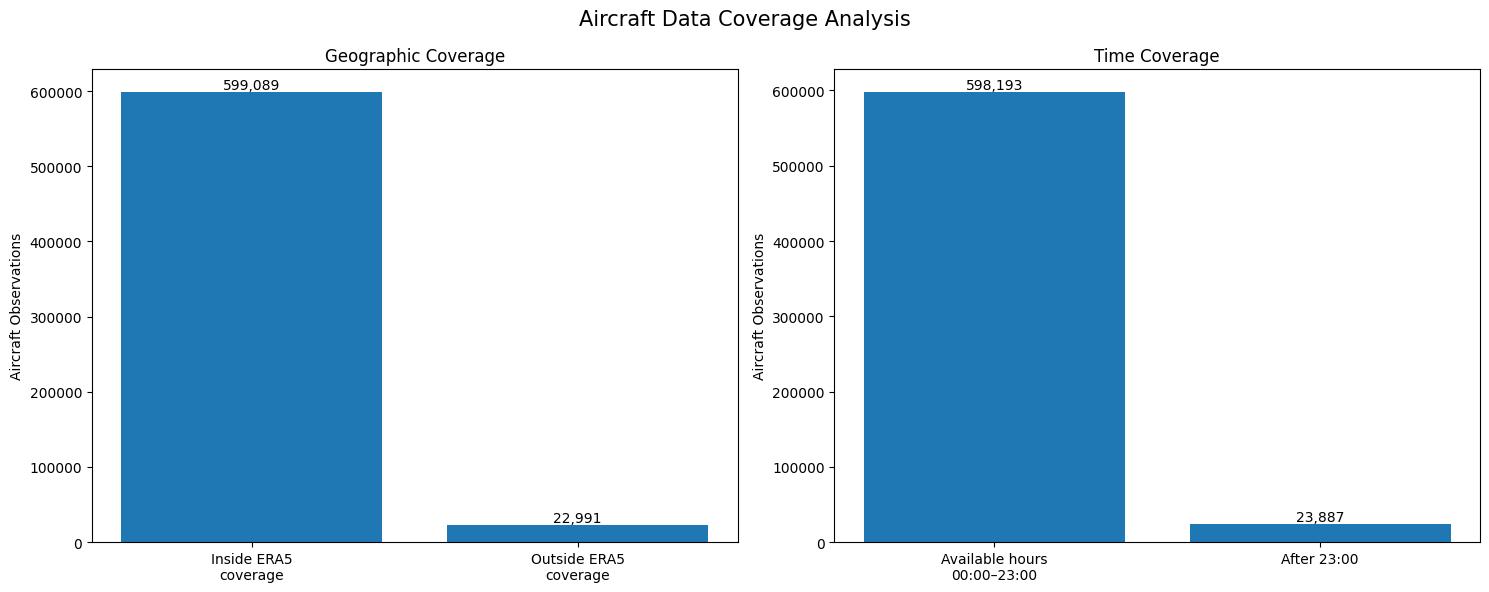

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Geographic coverage
axes[0].bar(
    ["Inside ERA5\ncoverage", "Outside ERA5\ncoverage"],
    [599089, 22991]
)

axes[0].set_title("Geographic Coverage")
axes[0].set_ylabel("Aircraft Observations")

axes[0].text(0, 599089, "599,089", ha="center", va="bottom")
axes[0].text(1, 22991, "22,991", ha="center", va="bottom")

# 2. Time coverage
axes[1].bar(
    ["Available hours\n00:00–23:00", "After 23:00"],
    [598193, 23887]
)

axes[1].set_title("Time Coverage")
axes[1].set_ylabel("Aircraft Observations")

axes[1].text(0, 598193, "598,193", ha="center", va="bottom")
axes[1].text(1, 23887, "23,887", ha="center", va="bottom")

plt.suptitle("Aircraft Data Coverage Analysis", fontsize=15)
plt.tight_layout()
plt.show()

In [23]:
# Step 9: Inspect pressure-level weather data

print("Pressure dataset:")
print(pressure)

print("\nAvailable variables:")
print(list(pressure.data_vars))

print("\nDimensions:")
print(pressure.sizes)

print("\nPressure levels:")
print(pressure["pressure_level"].values)

Pressure dataset:
<xarray.Dataset> Size: 3MB
Dimensions:                (valid_time: 24, pressure_level: 24, latitude: 13,
                            longitude: 13)
Coordinates:
  * valid_time             (valid_time) datetime64[ns] 192B 2026-10-01 ... 20...
  * pressure_level         (pressure_level) float64 192B 1e+03 975.0 ... 175.0
  * latitude               (latitude) float64 104B 23.0 22.75 ... 20.25 20.0
  * longitude              (longitude) float64 104B 38.0 38.25 ... 40.75 41.0
    number                 int64 8B ...
    expver                 (valid_time) <U4 384B ...
Data variables:
    u_component_of_wind    (valid_time, pressure_level, latitude, longitude) float32 389kB ...
    v_component_of_wind    (valid_time, pressure_level, latitude, longitude) float32 389kB ...
    temperature            (valid_time, pressure_level, latitude, longitude) float32 389kB ...
    geopotential           (valid_time, pressure_level, latitude, longitude) float32 389kB ...
    wind_speed   

In [24]:
# Step 10: Prepare pressure-level weather data

# Sort latitude in ascending order
pressure_sorted = pressure.sortby("latitude")

# Select pressure-level weather variables
pressure_weather_variables = [
    "u_component_of_wind",
    "v_component_of_wind",
    "wind_speed",
    "temperature_C",
    "geopotential_height_m"
]

print("Pressure dataset prepared successfully!")

print("\nVariables:")
print(list(pressure_sorted.data_vars))

print("\nPressure levels:")
print(pressure_sorted["pressure_level"].values)

print("\nDimensions:")
print(pressure_sorted.sizes)

Pressure dataset prepared successfully!

Variables:
['u_component_of_wind', 'v_component_of_wind', 'temperature', 'geopotential', 'wind_speed', 'temperature_C', 'geopotential_height_m']

Pressure levels:
[1000.  975.  950.  925.  900.  875.  850.  825.  800.  775.  750.  700.
  650.  600.  550.  500.  450.  400.  350.  300.  250.  225.  200.  175.]

Dimensions:
Frozen({'valid_time': 24, 'pressure_level': 24, 'latitude': 13, 'longitude': 13})


In [27]:
# Step 11: Estimate aircraft pressure from barometric altitude

T0 = 288.15       # Sea-level standard temperature (K)
P0 = 1013.25      # Sea-level standard pressure (hPa)
L = 0.0065        # Temperature lapse rate (K/m)
R = 287.05        # Specific gas constant (J/kg/K)
g = 9.80665       # Gravitational acceleration (m/s²)

# Convert barometric altitude from feet to meters
altitude_m = observations["barometric_altitude_ft"] * 0.3048

# Estimate atmospheric pressure
observations["estimated_pressure_hPa"] = P0 * (
    1 - (L * altitude_m / T0)
) ** (g / (R * L))

print("Aircraft pressure estimation completed!")

print("\nEstimated pressure statistics:")
print(observations["estimated_pressure_hPa"].describe())

Aircraft pressure estimation completed!

Estimated pressure statistics:
count    618178.000000
mean        754.840573
std         208.041256
min         186.891206
25%         667.578943
50%         808.175757
75%         915.680374
max        1014.165746
Name: estimated_pressure_hPa, dtype: float64


In [28]:
# Step 12: Check pressure-level coverage

min_pressure = pressure_sorted["pressure_level"].min().item()
max_pressure = pressure_sorted["pressure_level"].max().item()

valid_pressure = observations["estimated_pressure_hPa"].notna()

inside_pressure = (
    valid_pressure &
    observations["estimated_pressure_hPa"].between(
        min_pressure, max_pressure
    )
)

print("ERA5 pressure range:", min_pressure, "to", max_pressure, "hPa")

print("Valid aircraft pressure readings:", valid_pressure.sum())

print("Inside ERA5 pressure range:", inside_pressure.sum())

print("Outside ERA5 pressure range:",
      (valid_pressure & ~inside_pressure).sum())

print("Pressure coverage:",
      round(inside_pressure.sum() / valid_pressure.sum() * 100, 2), "%")

ERA5 pressure range: 175.0 to 1000.0 hPa
Valid aircraft pressure readings: 618178
Inside ERA5 pressure range: 575228
Outside ERA5 pressure range: 42950
Pressure coverage: 93.05 %


In [29]:
# Step 13: Prepare pressure-level weather columns

pressure_weather_columns = [
    "wind_u_pressure",
    "wind_v_pressure",
    "wind_speed_pressure",
    "temperature_pressure_C",
    "geopotential_height_m"
]

# Initialize columns with missing values
for col in pressure_weather_columns:
    observations[col] = np.nan

print("Pressure weather columns initialized!")
print(pressure_weather_columns)

Pressure weather columns initialized!
['wind_u_pressure', 'wind_v_pressure', 'wind_speed_pressure', 'temperature_pressure_C', 'geopotential_height_m']


In [30]:
# Check pressure matching inputs

print("Observation columns:")
print([
    "timestamp_utc",
    "latitude_deg",
    "longitude_deg",
    "estimated_pressure_hPa"
])

print("\nPressure dimensions:")
print(pressure_sorted.sizes)

print("\nPressure coordinates:")
print(list(pressure_sorted.coords))

Observation columns:
['timestamp_utc', 'latitude_deg', 'longitude_deg', 'estimated_pressure_hPa']

Pressure dimensions:
Frozen({'valid_time': 24, 'pressure_level': 24, 'latitude': 13, 'longitude': 13})

Pressure coordinates:
['number', 'valid_time', 'pressure_level', 'latitude', 'longitude', 'expver']


In [31]:
# Step 14: Match pressure-level weather with aircraft observations

# Prepare pressure dataset
pressure_sorted = pressure_sorted.sortby("latitude")

# Process observations in chunks
chunk_size = 50000

for start in range(0, len(observations), chunk_size):

    end = min(start + chunk_size, len(observations))

    chunk = observations.iloc[start:end]

    # Select observations with valid pressure
    valid = (
        chunk["estimated_pressure_hPa"].between(175, 1000) &
        chunk["latitude_deg"].between(20, 23) &
        chunk["longitude_deg"].between(38, 41)
    )

    if not valid.any():
        continue

    selected = chunk.loc[valid]

    # Prepare interpolation coordinates
    times = (
        selected["timestamp_utc"]
        .dt.tz_localize(None)
        .to_numpy()
    )

    pressures = selected["estimated_pressure_hPa"].to_numpy()

    latitudes = selected["latitude_deg"].to_numpy()

    longitudes = selected["longitude_deg"].to_numpy()

    # Interpolate weather variables
    weather = pressure_sorted[
        pressure_weather_variables
    ].interp(
        valid_time=xr.DataArray(times, dims="obs"),
        pressure_level=xr.DataArray(pressures, dims="obs"),
        latitude=xr.DataArray(latitudes, dims="obs"),
        longitude=xr.DataArray(longitudes, dims="obs"),
        method="linear"
    )

    # Save matched weather values
    observations.loc[selected.index, pressure_weather_columns] = np.column_stack([
        weather["u_component_of_wind"].values,
        weather["v_component_of_wind"].values,
        weather["wind_speed"].values,
        weather["temperature_C"].values,
        weather["geopotential_height_m"].values
    ])

    print(f"Processed {end:,} / {len(observations):,}")

print("\nPressure-level weather matching completed!")

Processed 50,000 / 622,080
Processed 100,000 / 622,080
Processed 150,000 / 622,080
Processed 200,000 / 622,080
Processed 250,000 / 622,080
Processed 300,000 / 622,080
Processed 350,000 / 622,080
Processed 400,000 / 622,080
Processed 450,000 / 622,080
Processed 500,000 / 622,080
Processed 550,000 / 622,080
Processed 600,000 / 622,080
Processed 622,080 / 622,080

Pressure-level weather matching completed!


In [32]:
# Step 15: Check pressure weather matching results

print("Total observations:", len(observations))

print("Matched observations:",
      observations["wind_speed_pressure"].notna().sum())

print("Missing observations:",
      observations["wind_speed_pressure"].isna().sum())

print("Coverage percentage:",
      round(
          observations["wind_speed_pressure"].notna().mean() * 100, 2
      ), "%")

print("\nMissing values by pressure variable:")
print(observations[pressure_weather_columns].isna().sum())

Total observations: 622080
Matched observations: 530488
Missing observations: 91592
Coverage percentage: 85.28 %

Missing values by pressure variable:
wind_u_pressure           91592
wind_v_pressure           91592
wind_speed_pressure       91592
temperature_pressure_C    91592
geopotential_height_m     91592
dtype: int64


In [33]:
# Step 16: Analyze missing pressure weather data

pressure_missing = observations["wind_speed_pressure"].isna()

missing_pressure = (
    ~observations["estimated_pressure_hPa"].between(175, 1000)
)

missing_location = (
    ~observations["latitude_deg"].between(20, 23) |
    ~observations["longitude_deg"].between(38, 41)
)

missing_time = (
    observations["timestamp_utc"].dt.tz_localize(None) >
    pressure_sorted["valid_time"].max().values
)

print("Total missing:", pressure_missing.sum())

print("Outside pressure range:",
      (pressure_missing & missing_pressure).sum())

print("Outside geographic coverage:",
      (pressure_missing & missing_location).sum())

print("Outside time range:",
      (pressure_missing & missing_time).sum())

Total missing: 91592
Outside pressure range: 46852
Outside geographic coverage: 22991
Outside time range: 24941


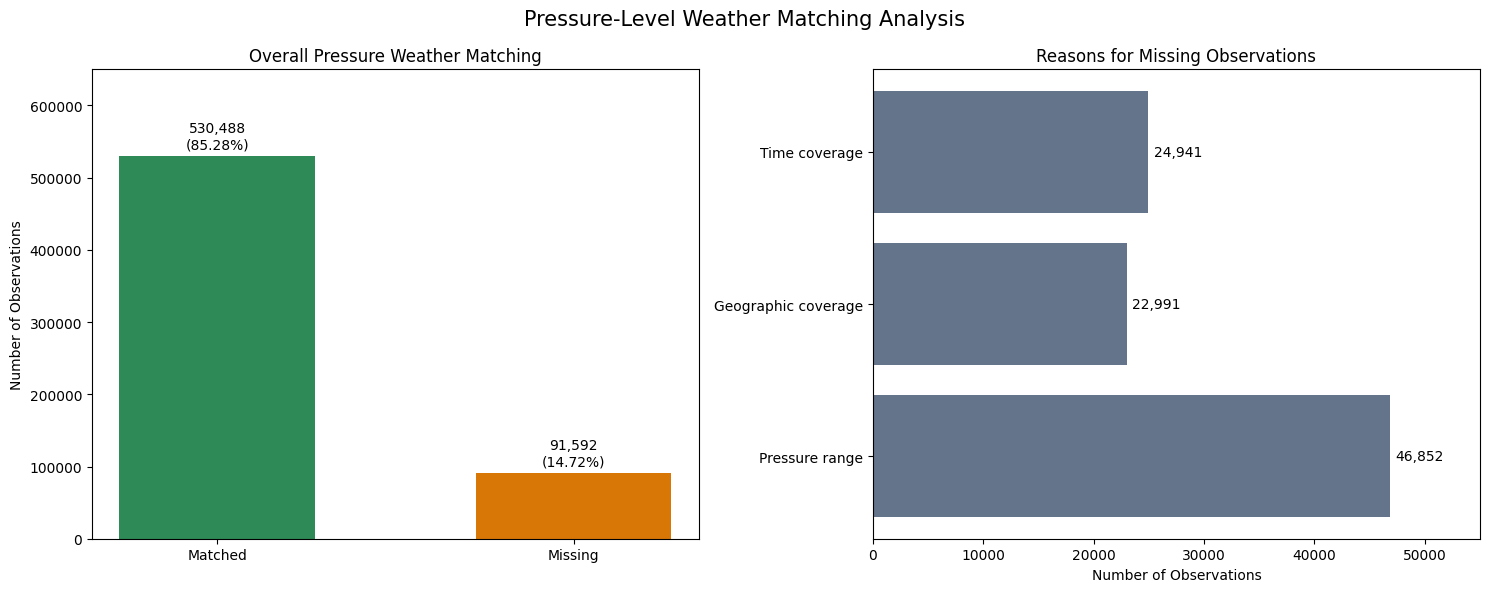

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Overall matching results
labels = ["Matched", "Missing"]
values = [530488, 91592]
colors = ["#2E8B57", "#D97706"]

axes[0].bar(labels, values, color=colors, width=0.55)

axes[0].set_title("Overall Pressure Weather Matching")
axes[0].set_ylabel("Number of Observations")
axes[0].set_ylim(0, 650000)

for i, value in enumerate(values):
    percentage = value / 622080 * 100
    axes[0].text(
        i, value + 10000,
        f"{value:,}\n({percentage:.2f}%)",
        ha="center"
    )

# Chart 2: Missing data reasons
reasons = [
    "Pressure range",
    "Geographic coverage",
    "Time coverage"
]

counts = [46852, 22991, 24941]

axes[1].barh(reasons, counts, color="#64748B")
axes[1].set_title("Reasons for Missing Observations")
axes[1].set_xlabel("Number of Observations")

for i, value in enumerate(counts):
    axes[1].text(value + 500, i, f"{value:,}", va="center")

axes[1].set_xlim(0, 55000)

fig.suptitle("Pressure-Level Weather Matching Analysis", fontsize=15)
plt.tight_layout()
plt.show()

In [37]:
# Step 18: Pressure-level weather summary

# Select observations with matched pressure weather
pressure_matched = observations[
    observations["wind_speed_pressure"].notna()
]

print("Total observations:", len(observations))
print("Matched pressure observations:", len(pressure_matched))

print("\nMissing pressure weather values:")
print(observations[pressure_weather_columns].isna().sum())

print("\nPressure-level weather statistics:")
display(pressure_matched[pressure_weather_columns].describe().round(2))

Total observations: 622080
Matched pressure observations: 530488

Missing pressure weather values:
wind_u_pressure           91592
wind_v_pressure           91592
wind_speed_pressure       91592
temperature_pressure_C    91592
geopotential_height_m     91592
dtype: int64

Pressure-level weather statistics:


,wind_u_pressure,wind_v_pressure,wind_speed_pressure,temperature_pressure_C,geopotential_height_m
count,530488.00,530488.00,530488.00,530488.00,530488.00
mean,0.88,3.46,4.90,14.99,2835.08
std,3.66,2.16,2.74,17.14,2500.24
min,-10.23,-8.79,0.32,-55.38,85.35
25%,-1.29,2.32,3.32,11.86,1027.92
50%,0.20,3.56,4.19,21.85,2054.09
75%,1.77,4.74,5.87,26.93,3340.88
max,21.59,11.10,23.15,31.65,12912.70


In [39]:
# Step 19: Save observations with weather data

observations.to_parquet(
    "observations_with_weather.parquet",
    index=False
)

print("Saved successfully!")
print("Rows:", len(observations))
print("Columns:", len(observations.columns))

Saved successfully!
Rows: 622080
Columns: 47


In [116]:
# Get unique aircraft from flights

aircraft_list = (
    flights[["icao24"]]
    .drop_duplicates()
    .copy()
)

aircraft_list["icao24"] = (
    aircraft_list["icao24"].astype(str).str.strip().str.upper()
)

print("Total flights:", len(flights))
print("Unique aircraft:", len(aircraft_list))

display(aircraft_list.head())

Total flights: 872
Unique aircraft: 339


,icao24
0,4BC84A
1,7609AF
2,0180A8
3,06A0B3
4,4BAAD2


In [48]:
aircraft_db = pd.read_sql_query(
    "SELECT * FROM aircrafts",
    conn
)

print("Total records:", len(aircraft_db))
print("Columns:", aircraft_db.columns.tolist())

display(aircraft_db.head())

Total records: 625588
Columns: ['aircraft_icao_address', 'aircraft_registration', 'aircraft_country', 'aircraft_serial_number', 'aircraft_type_code', 'aircraft_manufacturer_icao', 'aircraft_operator_icao']


,aircraft_icao_address,aircraft_registration,aircraft_country,aircraft_serial_number,aircraft_type_code,aircraft_manufacturer_icao,aircraft_operator_icao
0,004002,Z-WPA,Zimbabwe,23677,B732,BOEING,AZW
1,004006,Z-WSG,Zimbabwe,None,BE20,BEECH,None
2,004013,Z-FJF,Zimbabwe,None,E145,EMBRAER,None
3,004014,Z-RGM,Zimbabwe,None,B772,BOEING,None
4,004016,Z-DSA,Zimbabwe,None,C182,CESSNA,None


In [117]:
aircraft_db["aircraft_icao_address"] = (
    aircraft_db["aircraft_icao_address"]
    .astype(str).str.strip().str.upper()
)

aircraft_info = aircraft_list.merge(
    aircraft_db,
    left_on="icao24",
    right_on="aircraft_icao_address",
    how="left"
)

aircraft_info = aircraft_info.rename(columns={
    "aircraft_type_code": "typecode",
    "aircraft_registration": "registration",
    "aircraft_manufacturer_icao": "manufacturer",
    "aircraft_operator_icao": "operator"
})

print("Total aircraft:", len(aircraft_info))
print("Matched:", aircraft_info["typecode"].notna().sum())
print("Unmatched:", aircraft_info["typecode"].isna().sum())

display(aircraft_info.head())

Total aircraft: 339
Matched: 336
Unmatched: 3


,icao24,aircraft_icao_address,registration,aircraft_country,aircraft_serial_number,typecode,manufacturer,operator
0,4BC84A,4BC84A,TC-RBJ,Turkey,None,A21N,AIRBUS,None
1,7609AF,7609AF,AP-BMO,Pakistan,6067,A321,AIRBUS,ABQ
2,0180A8,0180A8,5A-BRE,Libya,None,A320,AIRBUS,BNL
3,06A0B3,06A0B3,A7-BCO,Qatar,38333,B788,BOEING,QTR
4,4BAAD2,4BAAD2,TC-JVR,Turkey,60030,B738,BOEING,THY


In [118]:
from openap import prop

aircraft_specs = []

for ac in aircraft_info["typecode"].dropna().unique():
    try:
        specs = prop.aircraft(ac, use_synonym=True)

        aircraft_specs.append({
            "typecode": ac,
            "aircraft_name": specs["aircraft"],
            "OEW_kg": specs["oew"],
            "MTOW_kg": specs["mtow"],
            "MLW_kg": specs["mlw"],
            "MFC_kg": specs["mfc"]
        })

    except Exception:
        continue

aircraft_specs = pd.DataFrame(aircraft_specs)

print("Aircraft specifications:", len(aircraft_specs))
display(aircraft_specs)

/usr/local/lib/python3.13/dist-packages/openap/prop.py:68: UserWarning: Aircraft: using synonym e170 for su95
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/openap/prop.py:68: UserWarning: Aircraft: using synonym b77w for b77l
  warnings.warn(


Aircraft specifications: 24


,typecode,aircraft_name,OEW_kg,MTOW_kg,MLW_kg,MFC_kg
0,A21N,Airbus A321neo,50000,97000,77800,33000
1,A321,Airbus A321,48500,93500,77800,30030
2,A320,Airbus A320,42600,78000,66000,24210
3,B788,Boeing 787-8,119000,228000,172000,126200
4,B738,Boeing 737-800,41400,79000,66300,26000
5,A343,Airbus A340-300,130000,276000,190000,147850
6,A20N,Airbus A320neo,44300,79000,66000,29700
7,A333,Airbus A330-300,122780,242000,188000,139000
8,A332,Airbus A330-200,120200,230000,182000,139000
9,B38M,Boeing 737 MAX 8,45000,82000,66300,26000


In [54]:
aircraft_info = aircraft_info.merge(
    aircraft_specs,
    on="typecode",
    how="left"
)

print("Total aircraft:", len(aircraft_info))
print("With OpenAP specifications:",
      aircraft_info["OEW_kg"].notna().sum())
print("Without specifications:",
      aircraft_info["OEW_kg"].isna().sum())

display(aircraft_info.head())

Total aircraft: 339
With OpenAP specifications: 316
Without specifications: 23


,icao24,aircraft_icao_address,registration,aircraft_country,aircraft_serial_number,typecode,manufacturer,operator,aircraft_name,OEW_kg,MTOW_kg,MLW_kg,MFC_kg
0,008AC3,008AC3,ZS-KXA,None,None,M20P,MOONEY,None,NaN,NaN,NaN,NaN,NaN
1,0100DD,0100DD,SU-GCO,Egypt,35561,B738,BOEING,MSR,Boeing 737-800,41400.0,79000.0,66300.0,26000.0
2,01010A,01010A,SU-GDB,Egypt,35567,B738,BOEING,MSR,Boeing 737-800,41400.0,79000.0,66300.0,26000.0
3,010144,010144,SU-GDX,Egypt,40757,B738,BOEING,MSR,Boeing 737-800,41400.0,79000.0,66300.0,26000.0
4,010153,010153,SU-GDP,Egypt,38290,B77W,BOEING,MSR,Boeing 777-300ER,167800.0,351500.0,251300.0,181300.0


In [55]:
# Normalize ICAO24 identifiers
flights["icao24"] = flights["icao24"].str.upper().str.strip()
aircraft_info["icao24"] = aircraft_info["icao24"].str.upper().str.strip()

# Merge flight data with aircraft information
flight_data = flights.merge(
    aircraft_info,
    on="icao24",
    how="left"
)

print("Total flights:", len(flight_data))
print("Flights with aircraft specifications:",
      flight_data["OEW_kg"].notna().sum())
print("Flights without specifications:",
      flight_data["OEW_kg"].isna().sum())

display(flight_data.head())

Total flights: 872
Flights with aircraft specifications: 828
Flights without specifications: 44


,anchor_ms,callsigns,end_ms,end_utc,evidence_note,extensions,flight_id,gaps,icao24,max_gap_s,...,aircraft_country,aircraft_serial_number,typecode,manufacturer,operator,aircraft_name,OEW_kg,MTOW_kg,MLW_kg,MFC_kg
0,1790812800074,[PGT695],1790814046012,2026-10-01 00:20:46.012,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-4bc84a-1790812800074,[],4BC84A,14.885,...,Turkey,None,A21N,AIRBUS,None,Airbus A321neo,50000.0,97000.0,77800.0,33000.0
1,1790812800358,[ABQ872],1790814686728,2026-10-01 00:31:26.728,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-7609af-1790812800358,"[[1790813967740, 1790814017542], [179081401754...",7609AF,67.540,...,Pakistan,6067,A321,AIRBUS,ABQ,Airbus A321,48500.0,93500.0,77800.0,30030.0
2,1790812800524,[BNL1536],1790814455860,2026-10-01 00:27:35.860,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-0180a8-1790812800524,[],0180A8,11.057,...,Libya,None,A320,AIRBUS,BNL,Airbus A320,42600.0,78000.0,66000.0,24210.0
3,1790812801504,[QTR1184],1790813888471,2026-10-01 00:18:08.471,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-06a0b3-1790812801504,"[[1790813327287, 1790813348634], [179081334863...",06A0B3,194.896,...,Qatar,38333,B788,BOEING,QTR,Boeing 787-8,119000.0,228000.0,172000.0,126200.0
4,1790812802110,[THY115],1790813438551,2026-10-01 00:10:38.551,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-4baad2-1790812802110,[],4BAAD2,10.644,...,Turkey,60030,B738,BOEING,THY,Boeing 737-800,41400.0,79000.0,66300.0,26000.0


In [56]:
departure_data = flight_data[
    flight_data["runway_status"] == "accepted_departure_candidate"
].copy()

fuel_candidate_data = departure_data[
    departure_data["OEW_kg"].notna()
].copy()

print("Departure candidates:", len(departure_data))
print("With OpenAP specifications:", len(fuel_candidate_data))
print("Without specifications:",
      departure_data["OEW_kg"].isna().sum())

display(fuel_candidate_data.head())

Departure candidates: 241
With OpenAP specifications: 226
Without specifications: 15


,anchor_ms,callsigns,end_ms,end_utc,evidence_note,extensions,flight_id,gaps,icao24,max_gap_s,...,aircraft_country,aircraft_serial_number,typecode,manufacturer,operator,aircraft_name,OEW_kg,MTOW_kg,MLW_kg,MFC_kg
122,1790825303171,[NMA177],1790826587930,2026-10-01 03:49:47.930,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-010236-1790825303171,"[[1790825242184, 1790825284969], [179082577703...",010236,42.785,...,Egypt,None,A320,AIRBUS,None,Airbus A320,42600.0,78000.0,66000.0,24210.0
124,1790825393348,"[KNE4402, KNE402]",1790826618345,2026-10-01 03:50:18.345,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-717ccc-1790825393348,"[[1790825295795, 1790825351180], [179082535967...",717CCC,55.385,...,Saudi Arabia,None,A20N,AIRBUS,None,Airbus A320neo,44300.0,79000.0,66000.0,29700.0
127,1790825520673,[FAD333],1790826229297,2026-10-01 03:43:49.297,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-7110fa-1790825520673,"[[1790825420116, 1790825481105], [179082548110...",7110FA,60.989,...,Saudi Arabia,None,A20N,AIRBUS,None,Airbus A320neo,44300.0,79000.0,66000.0,29700.0
128,1790825880691,[THY097],1790827142696,2026-10-01 03:59:02.696,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-4bb26c-1790825880691,"[[1790825784075, 1790825804935], [179082580493...",4BB26C,25.866,...,Turkey,None,A21N,AIRBUS,None,Airbus A321neo,50000.0,97000.0,77800.0,33000.0
130,1790826031881,[MSR666],1790827242492,2026-10-01 04:00:42.492,"Reconstructed departure candidate, not an offi...","{'aircraft_type': None, 'aircraft_type_status'...",OEJN-2026-10-01-010153-1790826031881,"[[1790825972339, 1790826008627], [179082691855...",010153,36.288,...,Egypt,38290,B77W,BOEING,MSR,Boeing 777-300ER,167800.0,351500.0,251300.0,181300.0


In [119]:
fuel_candidate_data = fuel_candidate_data.copy()

fuel_candidate_data["mass_80_kg"] = (
    fuel_candidate_data["MTOW_kg"] * 0.80
)

display(
    fuel_candidate_data[
        ["flight_id", "icao24", "typecode", "MTOW_kg", "mass_80_kg"]
    ].head(10)
)

,flight_id,icao24,typecode,MTOW_kg,mass_80_kg
122,OEJN-2026-10-01-010236-1790825303171,010236,A320,78000.0,62400.0
124,OEJN-2026-10-01-717ccc-1790825393348,717CCC,A20N,79000.0,63200.0
127,OEJN-2026-10-01-7110fa-1790825520673,7110FA,A20N,79000.0,63200.0
128,OEJN-2026-10-01-4bb26c-1790825880691,4BB26C,A21N,97000.0,77600.0
130,OEJN-2026-10-01-010153-1790826031881,010153,B77W,351500.0,281200.0
133,OEJN-2026-10-01-717c94-1790826247806,717C94,A20N,79000.0,63200.0
135,OEJN-2026-10-01-7103f3-1790826555679,7103F3,A320,78000.0,62400.0
136,OEJN-2026-10-01-717cbf-1790826661103,717CBF,A20N,79000.0,63200.0
138,OEJN-2026-10-01-717cb6-1790826804733,717CB6,A20N,79000.0,63200.0
139,OEJN-2026-10-01-717cb2-1790826904784,717CB2,A20N,79000.0,63200.0


In [120]:
# Step 28: Select one sample flight

sample_flight = fuel_candidate_data.iloc[0]

print("Flight ID:", sample_flight["flight_id"])
print("Aircraft:", sample_flight["typecode"])
print("ICAO24:", sample_flight["icao24"])
print("Estimated Mass (kg):", sample_flight["mass_80_kg"])

Flight ID: OEJN-2026-10-01-010236-1790825303171
Aircraft: A320
ICAO24: 010236
Estimated Mass (kg): 62400.0


In [121]:
# Step 29: Get observations for the selected flight

flight_observations = observations[
    (observations["icao24"].astype(str).str.upper()
     == str(sample_flight["icao24"]).upper()) &
    (observations["timestamp_ms"] >= sample_flight["anchor_ms"]) &
    (observations["timestamp_ms"] <= sample_flight["end_ms"])
].copy()

flight_observations = flight_observations.sort_values(
    "timestamp_ms"
).reset_index(drop=True)

print("Flight observations:", len(flight_observations))
display(flight_observations.head())

Flight observations: 728


,schema_version,observation_id,source_file,source_row,source,icao24,timestamp_utc,timestamp_ms,latitude_deg,longitude_deg,...,wind_v_10m,wind_speed_10m,temperature_2m_C,surface_pressure_hPa,estimated_pressure_hPa,wind_u_pressure,wind_v_pressure,wind_speed_pressure,temperature_pressure_C,geopotential_height_m
0,1,20890fb98aa5da5e57ff32ae6712af53012e1ffa35b547...,/content/SANS/A2/wingbits_2026-10-01_03.parquet,3218,Wingbits evaluation sample,010236,2026-10-01 03:28:23.171000+00:00,1790825303171,21.685848,39.155172,...,0.956774,1.024596,29.399630,1004.194220,1008.681309,NaN,NaN,NaN,NaN,NaN
1,1,9326658356d74df5ae645ff92a8b4a3854d4331aac463a...,/content/SANS/A2/wingbits_2026-10-01_03.parquet,6587,Wingbits evaluation sample,010236,2026-10-01 03:28:25.208000+00:00,1790825305208,21.687515,39.154524,...,0.957456,1.025353,29.402293,1004.209950,1006.858509,NaN,NaN,NaN,NaN,NaN
2,1,2e3681d126aeca5e3b59685df479fcfe00feae380a41fb...,/content/SANS/A2/wingbits_2026-10-01_03.parquet,8113,Wingbits evaluation sample,010236,2026-10-01 03:28:26.158000+00:00,1790825306158,21.688269,39.154256,...,0.957790,1.025708,29.403465,1004.216218,1005.948110,NaN,NaN,NaN,NaN,NaN
3,1,bfbfbffd2f1d655cbbb1182d3ff1040c44be19be1bd2bc...,/content/SANS/A2/wingbits_2026-10-01_03.parquet,11481,Wingbits evaluation sample,010236,2026-10-01 03:28:27.301000+00:00,1790825307301,21.689209,39.153875,...,0.958161,1.026128,29.404988,1004.225618,1004.129312,NaN,NaN,NaN,NaN,NaN
4,1,689dd0775dadc8cc1ce8544209c8b46ff65083b27621f9...,/content/SANS/A2/wingbits_2026-10-01_03.parquet,13063,Wingbits evaluation sample,010236,2026-10-01 03:28:28.208000+00:00,1790825308208,21.689941,39.153576,...,0.958447,1.026453,29.406178,1004.233020,1003.220912,NaN,NaN,NaN,NaN,NaN


In [122]:
# Step 30: Check observation data

columns_to_check = [
    "timestamp_ms",
    "barometric_altitude_ft",
    "barometric_rate_fpm",
    "ground_speed_kt",
    "track_deg"
]

display(flight_observations[columns_to_check].describe())

,timestamp_ms,barometric_altitude_ft,barometric_rate_fpm,ground_speed_kt,track_deg
count,7.280000e+02,728.000000,728.000000,728.000000,728.000000
mean,1.790826e+12,10752.678571,1927.384615,307.979396,325.712885
std,3.319455e+05,8547.297591,715.168856,71.417092,7.477433
min,1.790825e+12,125.000000,64.000000,176.000000,318.809998
25%,1.790825e+12,3993.750000,1472.000000,270.600000,319.279999
50%,1.790826e+12,7937.500000,1920.000000,278.400000,322.839996
75%,1.790826e+12,16293.750000,2176.000000,390.900000,325.634995
max,1.790827e+12,31000.000000,4032.000000,442.700000,340.299988


In [123]:
# Step 30: Filter departure observations

departure_observations = flight_observations[
    flight_observations["barometric_altitude_ft"] <= 10000
].copy()

departure_observations = departure_observations.sort_values(
    "timestamp_ms"
).reset_index(drop=True)

print("Departure observations:", len(departure_observations))
print("Minimum altitude:",
      departure_observations["barometric_altitude_ft"].min())
print("Maximum altitude:",
      departure_observations["barometric_altitude_ft"].max())

Departure observations: 465
Minimum altitude: 125.0
Maximum altitude: 10000.0


In [124]:
# Step 31: Estimate True Airspeed

wind_u = departure_observations["wind_u_pressure"].fillna(
    departure_observations["wind_u_10m"]
)

wind_v = departure_observations["wind_v_pressure"].fillna(
    departure_observations["wind_v_10m"]
)

track_rad = np.deg2rad(departure_observations["track_deg"])

along_track_wind = (
    wind_u * np.sin(track_rad) +
    wind_v * np.cos(track_rad)
)

departure_observations["TAS_kt"] = (
    departure_observations["ground_speed_kt"]
    - along_track_wind * 1.94384
)

display(
    departure_observations[
        ["ground_speed_kt", "TAS_kt"]
    ].describe()
)

,ground_speed_kt,TAS_kt
count,465.000000,465.000000
mean,262.829677,259.294765
std,29.791347,29.472282
min,176.000000,173.094071
25%,262.400000,260.964414
50%,273.100000,271.964046
75%,278.000000,274.969613
max,286.900000,279.008371


In [125]:
# Step 32: Check missing values

required_columns = [
    "timestamp_ms",
    "barometric_altitude_ft",
    "barometric_rate_fpm",
    "TAS_kt"
]

print(departure_observations[required_columns].isna().sum())

timestamp_ms              0
barometric_altitude_ft    0
barometric_rate_fpm       0
TAS_kt                    0
dtype: int64


In [127]:
#OpenAP FuelFlow model

fuel_model = FuelFlow(ac=sample_flight["typecode"])

print("Aircraft:", sample_flight["typecode"])
print("Mass:", sample_flight["mass_80_kg"], "kg")

Aircraft: A320
Mass: 62400.0 kg


In [128]:
# Step 34: Calculate fuel flow

departure_observations["fuel_flow_kg_s"] = fuel_model.enroute(
    mass=sample_flight["mass_80_kg"],
    tas=departure_observations["TAS_kt"],
    alt=departure_observations["barometric_altitude_ft"],
    vs=departure_observations["barometric_rate_fpm"]
)

display(
    departure_observations[
        ["barometric_altitude_ft", "TAS_kt",
         "barometric_rate_fpm", "fuel_flow_kg_s"]
    ].head(10)
)

,barometric_altitude_ft,TAS_kt,barometric_rate_fpm,fuel_flow_kg_s
0,125.0,181.499125,704.0,1.164074
1,175.0,184.598831,1216.0,1.422347
2,200.0,184.294914,1408.0,1.513210
3,250.0,185.193686,1856.0,1.690274
4,275.0,185.193765,1856.0,1.690347
5,300.0,184.295002,2112.0,1.781017
6,375.0,183.860046,2624.0,1.920108
7,425.0,180.987401,3008.0,2.004251
8,475.0,180.909758,3136.0,2.024125
9,525.0,180.832483,3136.0,2.024427


In [129]:
# Step 35: Fuel flow statistics

print(departure_observations["fuel_flow_kg_s"].describe())

print(
    "Missing fuel flow:",
    departure_observations["fuel_flow_kg_s"].isna().sum()
)

print(
    "Non-positive fuel flow:",
    (departure_observations["fuel_flow_kg_s"] <= 0).sum()
)

count    465.000000
mean       1.555307
std        0.216053
min        0.725025
25%        1.457990
50%        1.532530
75%        1.676581
max        2.075832
Name: fuel_flow_kg_s, dtype: float64
Missing fuel flow: 0
Non-positive fuel flow: 0


In [130]:
# Step 36: Calculate time intervals

departure_observations["time_seconds"] = (
    departure_observations["timestamp_ms"] -
    departure_observations["timestamp_ms"].iloc[0]
) / 1000

print("Duration (minutes):",
      departure_observations["time_seconds"].iloc[-1] / 60)

print("First intervals:")
display(departure_observations[
    ["timestamp_utc", "time_seconds", "fuel_flow_kg_s"]
].head())

Duration (minutes): 4.972783333333334
First intervals:


,timestamp_utc,time_seconds,fuel_flow_kg_s
0,2026-10-01 03:28:23.171000+00:00,0.000,1.164074
1,2026-10-01 03:28:25.208000+00:00,2.037,1.422347
2,2026-10-01 03:28:26.158000+00:00,2.987,1.513210
3,2026-10-01 03:28:27.301000+00:00,4.130,1.690274
4,2026-10-01 03:28:28.208000+00:00,5.037,1.690347


In [131]:
# Step 37: Calculate total departure fuel

total_departure_fuel_kg = np.trapezoid(
    departure_observations["fuel_flow_kg_s"],
    x=departure_observations["time_seconds"]
)

print("Total Departure Fuel:",
      round(total_departure_fuel_kg, 2), "kg")

Total Departure Fuel: 446.32 kg


In [132]:
# Step 39: Check FuelFlow support

from openap import FuelFlow

aircraft_types = fuel_candidate_data["typecode"].dropna().unique()

supported_aircraft = []
unsupported_aircraft = []

for ac in aircraft_types:
    try:
        FuelFlow(ac=ac)
        supported_aircraft.append(ac)
    except Exception as e:
        unsupported_aircraft.append({
            "typecode": ac,
            "error": str(e)
        })

print("Supported:", len(supported_aircraft))
print("Unsupported:", len(unsupported_aircraft))

print("\nSupported aircraft:")
print(supported_aircraft)

print("\nUnsupported aircraft:")
display(pd.DataFrame(unsupported_aircraft))

Supported: 16
Unsupported: 2

Supported aircraft:
['A320', 'A20N', 'B77W', 'A333', 'B788', 'A321', 'B789', 'B38M', 'B738', 'A332', 'A388', 'A359', 'B739', 'B737', 'A343', 'B744']

Unsupported aircraft:


,typecode,error
0,A21N,Drag polar for a21n not available. Try to set ...
1,B77L,Aircraft b77l not available. Try to set `use_s...


In [138]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=UserWarning,
    module=r"openap\.(drag|prop)"
)


In [139]:
# Step 40: Test alternative aircraft names

from openap import FuelFlow

for ac in ["A21N", "B77L", "B77W"]:
    try:
        model = FuelFlow(ac=ac)
        print(ac, "-> Supported")
    except Exception as e:
        print(ac, "-> Unsupported:", str(e))

A21N -> Unsupported: Drag polar for a21n not available. Try to set `use_synonym=True` to initialize the object.
B77L -> Unsupported: Aircraft b77l not available. Try to set `use_synonym=True` to initialize the object.
B77W -> Supported


In [140]:
# Step 42: Test FuelFlow with synonyms

for ac in ["A21N", "B77L"]:
    try:
        model = FuelFlow(ac=ac, use_synonym=True)
        print(ac, "-> Supported with synonym")
    except Exception as e:
        print(ac, "-> Still unsupported:", str(e))

A21N -> Supported with synonym
B77L -> Supported with synonym


In [136]:
# Step 43: Check all aircraft using synonyms
# Suppress OpenAP UserWarnings

from openap import FuelFlow

supported_aircraft = []
unsupported_aircraft = []

for ac in fuel_candidate_data["typecode"].dropna().unique():
    try:
        FuelFlow(ac=ac, use_synonym=True)
        supported_aircraft.append(ac)
    except Exception as e:
        unsupported_aircraft.append({
            "typecode": ac,
            "error": str(e)
        })

print("Supported:", len(supported_aircraft))
print(supported_aircraft)

print("Unsupported:", len(unsupported_aircraft))
display(pd.DataFrame(unsupported_aircraft))

Supported: 18
['A320', 'A20N', 'A21N', 'B77W', 'A333', 'B788', 'A321', 'B789', 'B38M', 'B738', 'A332', 'A388', 'A359', 'B739', 'B77L', 'B737', 'A343', 'B744']
Unsupported: 0


""


In [143]:
supported_fuel_data = fuel_candidate_data[
    fuel_candidate_data["typecode"].isin(supported_aircraft)
].copy()

unsupported_fuel_data = fuel_candidate_data[
    ~fuel_candidate_data["typecode"].isin(supported_aircraft)
].copy()

print("Total fuel candidates:", len(fuel_candidate_data))
print("Supported flights:", len(supported_fuel_data))
print("Unsupported flights:", len(unsupported_fuel_data))

Total fuel candidates: 226
Supported flights: 226
Unsupported flights: 0


In [145]:
# Step 45: Define departure fuel calculation

def calculate_departure_fuel(flight, observations):

    ac = flight["typecode"]
    mass = flight["mass_80_kg"]

    obs = observations[
        (observations["icao24"].astype(str).str.upper()
         == str(flight["icao24"]).upper()) &
        (observations["timestamp_ms"] >= flight["anchor_ms"]) &
        (observations["timestamp_ms"] <= flight["end_ms"])
    ].copy()

    obs = obs.sort_values("timestamp_ms")

    obs = obs[
        obs["barometric_altitude_ft"] <= 10000
    ].copy()

    if len(obs) < 2:
        raise ValueError("Insufficient departure observations")

    wind_u = obs["wind_u_pressure"].fillna(obs["wind_u_10m"])
    wind_v = obs["wind_v_pressure"].fillna(obs["wind_v_10m"])

    track_rad = np.deg2rad(obs["track_deg"])

    along_track_wind = (
        wind_u * np.sin(track_rad) +
        wind_v * np.cos(track_rad)
    )

    obs["TAS_kt"] = (
        obs["ground_speed_kt"] - along_track_wind * 1.94384
    )

    obs = obs.dropna(subset=[
        "timestamp_ms",
        "barometric_altitude_ft",
        "barometric_rate_fpm",
        "TAS_kt"
    ])

    obs = obs[obs["TAS_kt"] > 0].copy()

    if len(obs) < 2:
        raise ValueError("Insufficient valid observations")

    model = FuelFlow(ac=ac, use_synonym=True)

    obs["fuel_flow_kg_s"] = model.enroute(
        mass=mass,
        tas=obs["TAS_kt"],
        alt=obs["barometric_altitude_ft"],
        vs=obs["barometric_rate_fpm"]
    )

    obs["time_seconds"] = (
        obs["timestamp_ms"] - obs["timestamp_ms"].iloc[0]
    ) / 1000

    total_fuel = np.trapezoid(
        obs["fuel_flow_kg_s"],
        x=obs["time_seconds"]
    )

    return {
        "flight_id": flight["flight_id"],
        "icao24": flight["icao24"],
        "aircraft_type": ac,
        "estimated_mass_kg": mass,
        "departure_points": len(obs),
        "departure_duration_min": (
            obs["time_seconds"].iloc[-1] / 60
        ),
        "total_departure_fuel_kg": total_fuel
    }

In [146]:
# Step 46: Calculate fuel for all supported flights

flight_results = []
failed_flights = []

for _, flight in supported_fuel_data.iterrows():

    try:
        result = calculate_departure_fuel(
            flight,
            observations
        )
        flight_results.append(result)

    except Exception as e:
        failed_flights.append({
            "flight_id": flight["flight_id"],
            "typecode": flight["typecode"],
            "error": str(e)
        })

fuel_results = pd.DataFrame(flight_results)
failed_flights_df = pd.DataFrame(failed_flights)

print("Successfully calculated:", len(fuel_results))
print("Failed flights:", len(failed_flights_df))

display(fuel_results.head())

Successfully calculated: 205
Failed flights: 21


,flight_id,icao24,aircraft_type,estimated_mass_kg,departure_points,departure_duration_min,total_departure_fuel_kg
0,OEJN-2026-10-01-010236-1790825303171,010236,A320,62400.0,465,4.972783,446.321212
1,OEJN-2026-10-01-717ccc-1790825393348,717CCC,A20N,63200.0,438,4.046383,264.378216
2,OEJN-2026-10-01-7110fa-1790825520673,7110FA,A20N,63200.0,439,4.523700,281.669995
3,OEJN-2026-10-01-4bb26c-1790825880691,4BB26C,A21N,77600.0,487,5.473667,394.830465
4,OEJN-2026-10-01-010153-1790826031881,010153,B77W,281200.0,572,5.319950,1956.526287


In [147]:
# Step 47: Investigate failed flights

print("Failed flights:", len(failed_flights_df))

display(
    failed_flights_df["error"]
    .value_counts()
    .reset_index(name="count")
)

Failed flights: 21


,error,count
0,Insufficient valid observations,20
1,Insufficient departure observations,1


In [154]:
# Keep successfully calculated flights only

final_fuel_results = fuel_results.copy()

print("Total original flights:", len(fuel_candidate_data))
print("Successfully calculated:", len(final_fuel_results))
print("Excluded flights:", len(failed_flights_df))
print("Final dataset:", len(final_fuel_results))

display(final_fuel_results.head())

Total original flights: 226
Successfully calculated: 205
Excluded flights: 21
Final dataset: 205


,flight_id,icao24,aircraft_type,estimated_mass_kg,departure_points,departure_duration_min,total_departure_fuel_kg
0,OEJN-2026-10-01-010236-1790825303171,010236,A320,62400.0,465,4.972783,446.321212
1,OEJN-2026-10-01-717ccc-1790825393348,717CCC,A20N,63200.0,438,4.046383,264.378216
2,OEJN-2026-10-01-7110fa-1790825520673,7110FA,A20N,63200.0,439,4.523700,281.669995
3,OEJN-2026-10-01-4bb26c-1790825880691,4BB26C,A21N,77600.0,487,5.473667,394.830465
4,OEJN-2026-10-01-010153-1790826031881,010153,B77W,281200.0,572,5.319950,1956.526287


In [ ]:
# Step 56: Save final fuel results

final_fuel_results.to_csv(
    "OEJN_departure_fuel_results.csv",
    index=False
)

final_fuel_results.to_parquet(
    "OEJN_departure_fuel_results.parquet",
    index=False
)
print("Files saved successfully!")

In [166]:
print(final_fuel_results.columns.tolist())

['flight_id', 'icao24', 'aircraft_type', 'estimated_mass_kg', 'departure_points', 'departure_duration_min', 'total_departure_fuel_kg']


In [167]:

from openap import FuelFlow
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore", category=UserWarning)


def calculate_fuel_points(flight, observations):

    ac = flight["typecode"]
    mass = flight["mass_80_kg"]

    obs = observations[
        (observations["icao24"].astype(str).str.upper()
         == str(flight["icao24"]).upper()) &
        (observations["timestamp_ms"] >= flight["anchor_ms"]) &
        (observations["timestamp_ms"] <= flight["end_ms"])
    ].copy()

    obs = obs.sort_values("timestamp_ms")
    obs = obs[obs["barometric_altitude_ft"] <= 10000].copy()

    if len(obs) < 2:
        return None

    # Original TAS calculation
    wind_u = obs["wind_u_pressure"].fillna(obs["wind_u_10m"])
    wind_v = obs["wind_v_pressure"].fillna(obs["wind_v_10m"])

    track_rad = np.deg2rad(obs["track_deg"])

    along_track_wind = (
        wind_u * np.sin(track_rad) +
        wind_v * np.cos(track_rad)
    )

    obs["TAS_kt"] = (
        obs["ground_speed_kt"] - along_track_wind * 1.94384
    )

    obs = obs.dropna(subset=[
        "timestamp_ms",
        "barometric_altitude_ft",
        "barometric_rate_fpm",
        "TAS_kt"
    ])

    obs = obs[obs["TAS_kt"] > 0].copy()

    if len(obs) < 2:
        return None

    model = FuelFlow(ac=ac, use_synonym=True)

    obs["fuel_flow_kg_s"] = model.enroute(
        mass=mass,
        tas=obs["TAS_kt"],
        alt=obs["barometric_altitude_ft"],
        vs=obs["barometric_rate_fpm"]
    )

    obs["flight_id"] = flight["flight_id"]
    obs["aircraft_type"] = ac
    obs["estimated_mass_kg"] = mass

    return obs


# Select successful flights
successful_flights = supported_fuel_data[
    supported_fuel_data["flight_id"].isin(fuel_results["flight_id"])
]

# Calculate fuel flow for each flight
fuel_points_list = []

for _, flight in tqdm(
    successful_flights.iterrows(),
    total=len(successful_flights)
):
    points = calculate_fuel_points(flight, observations)

    if points is not None:
        fuel_points_list.append(points)

if not fuel_points_list:
    raise ValueError("No fuel-flow data was generated.")


# Combine all observations
weather_fuel_dataset = pd.concat(
    fuel_points_list,
    ignore_index=True
)


# Add total departure fuel consumption
total_fuel = final_fuel_results[
    ["flight_id", "total_departure_fuel_kg"]
].drop_duplicates(subset=["flight_id"])

weather_fuel_dataset = weather_fuel_dataset.merge(
    total_fuel,
    on="flight_id",
    how="left"
)


# Select important columns
selected_columns = [
    "flight_id",
    "icao24",
    "aircraft_type",
    "timestamp_utc",
    "timestamp_ms",
    "latitude",
    "longitude",
    "estimated_mass_kg",
    "barometric_altitude_ft",
    "barometric_rate_fpm",
    "ground_speed_kt",
    "track_deg",
    "TAS_kt",
    "wind_u_pressure",
    "wind_v_pressure",
    "wind_u_10m",
    "wind_v_10m",
    "temperature_2m_C",
    "wind_speed_10m",
    "surface_pressure_hPa",
    "fuel_flow_kg_s",
    "total_departure_fuel_kg"
]

# Keep available columns
selected_columns = [
    col for col in selected_columns
    if col in weather_fuel_dataset.columns
]

weather_fuel_dataset = weather_fuel_dataset[selected_columns].copy()


# Sort by flight and timestamp
weather_fuel_dataset = weather_fuel_dataset.sort_values(
    ["flight_id", "timestamp_ms"]
).reset_index(drop=True)


# Save the dataset
weather_fuel_dataset.to_csv(
    "Weather_FuelFlow_Dataset.csv",
    index=False
)

weather_fuel_dataset.to_parquet(
    "Weather_FuelFlow_Dataset.parquet",
    index=False
)


# Display dataset summary
print("Dataset saved successfully!")
print("Total observations:", len(weather_fuel_dataset))
print("Unique flights:", weather_fuel_dataset["flight_id"].nunique())
print("Total features:", len(weather_fuel_dataset.columns))
print("Missing Fuel Flow:", weather_fuel_dataset["fuel_flow_kg_s"].isna().sum())
print("Missing Total Departure Fuel:",
      weather_fuel_dataset["total_departure_fuel_kg"].isna().sum())

print("\nDataset columns:")
print(weather_fuel_dataset.columns.tolist())

display(weather_fuel_dataset.head())


  0%|          | 0/205 [00:00<?, ?it/s]

Dataset saved successfully!
Total observations: 94102
Unique flights: 205
Total features: 20
Missing Fuel Flow: 0
Missing Total Departure Fuel: 0

Dataset columns:
['flight_id', 'icao24', 'aircraft_type', 'timestamp_utc', 'timestamp_ms', 'estimated_mass_kg', 'barometric_altitude_ft', 'barometric_rate_fpm', 'ground_speed_kt', 'track_deg', 'TAS_kt', 'wind_u_pressure', 'wind_v_pressure', 'wind_u_10m', 'wind_v_10m', 'temperature_2m_C', 'wind_speed_10m', 'surface_pressure_hPa', 'fuel_flow_kg_s', 'total_departure_fuel_kg']


,flight_id,icao24,aircraft_type,timestamp_utc,timestamp_ms,estimated_mass_kg,barometric_altitude_ft,barometric_rate_fpm,ground_speed_kt,track_deg,TAS_kt,wind_u_pressure,wind_v_pressure,wind_u_10m,wind_v_10m,temperature_2m_C,wind_speed_10m,surface_pressure_hPa,fuel_flow_kg_s,total_departure_fuel_kg
0,OEJN-2026-10-01-0100dd-1790887195138,0100dd,B738,2026-10-01 20:39:55.138000+00:00,1790887195138,63200.0,175.0,1536.0,177.5,340.239990,179.928635,NaN,NaN,-0.412045,-1.475593,29.781423,1.734987,1005.618039,1.666001,576.071938
1,OEJN-2026-10-01-0100dd-1790887195138,0100dd,B738,2026-10-01 20:39:55.654000+00:00,1790887195654,63200.0,175.0,1856.0,178.1,340.649994,180.539846,NaN,NaN,-0.412146,-1.475050,29.781277,1.734628,1005.621822,1.800583,576.071938
2,OEJN-2026-10-01-0100dd-1790887195138,0100dd,B738,2026-10-01 20:39:56.225000+00:00,1790887196225,63200.0,200.0,2048.0,178.1,340.649994,180.538775,NaN,NaN,-0.412274,-1.474511,29.781134,1.734269,1005.625436,1.870733,576.071938
3,OEJN-2026-10-01-0100dd-1790887195138,0100dd,B738,2026-10-01 20:39:57.172000+00:00,1790887197172,63200.0,225.0,2176.0,178.1,340.649994,180.536685,NaN,NaN,-0.412572,-1.473476,29.780888,1.733566,1005.631221,1.912183,576.071938
4,OEJN-2026-10-01-0100dd-1790887195138,0100dd,B738,2026-10-01 20:39:57.580000+00:00,1790887197580,63200.0,250.0,2304.0,178.1,340.649994,180.535788,NaN,NaN,-0.412617,-1.473003,29.780749,1.733254,1005.634930,1.949447,576.071938


In [170]:
from google.colab import files

files.download("Weather_FuelFlow_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>